# Del 1 – Analys av Health Study

I den här uppgiften analyserar vi data från en hälsostudie.
Datasetet innehåller följande kolumner:

- **age:** Patientens ålder i år.
- **sex:** Patientens kön (M = män, F = kvinnor).
- **height:** Patientens längd i cm.
- **weight:** Patientens vikt i kg.
- **systolic_bp:** Systoliskt blodtryck (mmHg).
- **cholesterol:** Kolesterolvärde i blodet (mmol/L).
- **smoker:** Rökstatus (Yes = rökare, No = icke-rökare).
- **disease:** Sjukdomsstatus (1 = sjukdom, 0 = ingen sjukdom).

In [2]:
# vi börjar med att kalla bibioltek som vi behöver för att analysera data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from pathlib import Path
import sys; sys.path.append("..") 

df = pd.read_csv("../data/health_study_dataset.csv") # läser in data från csv filen
print(df.head()) # visar de första raderna i dataframen
print("_______________________")
print(df.info()) # visar information om dataframen


   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0
_______________________
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non

In [3]:
print(f" Totala rader inann rensning och kontroll {len(df)}") # visar antal rader och kolumner i dataframen
df = df.dropna() # tar bort rader med NaN värden
print(f" Unika värden i kolumnen: {df['id'].nunique()}") # visar antal unika värden i kolumnen
df = df.drop_duplicates() # tar bort dubbletter
print(f" Totala rader efter rensning och kontroll {len(df)}") # visar antal rader och kolumner i dataframen

 Totala rader inann rensning och kontroll 800
 Unika värden i kolumnen: 800
 Totala rader efter rensning och kontroll 800


In [4]:
print(df.describe()) # visar statistik om dataframen


             id         age      height      weight  systolic_bp  cholesterol  \
count  800.0000  800.000000  800.000000  800.000000   800.000000   800.000000   
mean   400.5000   49.426250  171.849250   73.413000   149.178625     4.929150   
std    231.0844   14.501118    9.804259   13.685059    12.793360     0.848413   
min      1.0000   18.000000  144.400000   33.700000   106.800000     2.500000   
25%    200.7500   39.000000  164.775000   64.800000   140.900000     4.327500   
50%    400.5000   50.000000  171.350000   73.200000   149.400000     4.970000   
75%    600.2500   59.000000  178.925000   82.600000   157.600000     5.482500   
max    800.0000   90.000000  200.400000  114.400000   185.900000     7.880000   

          disease  
count  800.000000  
mean     0.058750  
std      0.235303  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      0.000000  
max      1.000000  


In [5]:
df[["age","weight","height","systolic_bp","cholesterol"]].agg(['mean', 'median', 'min', 'max'])  # visar statistik om kolumnerna

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


### Tolkning av beskrivande statistik

Tabellen visar medelvärde, median, minimum och maximum för de numeriska variablerna.

Studien omfattar vuxna personer i åldern 18–90 år och innehåller uppgifter om både rökare och icke-rökare.

Medelåldern är 49,43 år och medelvikten är 73,41 kg. Det genomsnittliga systoliska blodtrycket är 149,18 mmHg och kolesterolvärdet är i genomsnitt 4,93 mmol/L.

Medelvärde och median ligger nära varandra för samtliga variabler, vilket tyder på att det inte finns någon tydlig snedfördelning utifrån dessa mått. För att undersöka fördelningarna närmare behövs ytterligare analys.

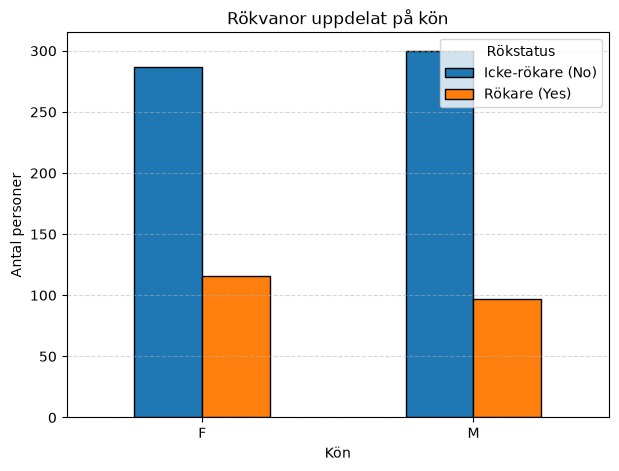

In [6]:
smoke_sex = pd.crosstab(df["sex"], df["smoker"])

smoke_sex.plot(kind='bar', figsize=(7, 5), edgecolor='black', rot=0)

plt.title("Rökvanor uppdelat på kön")
plt.xlabel("Kön")
plt.ylabel("Antal personer")
plt.legend(["Icke-rökare (No)", "Rökare (Yes)"], title='Rökstatus')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

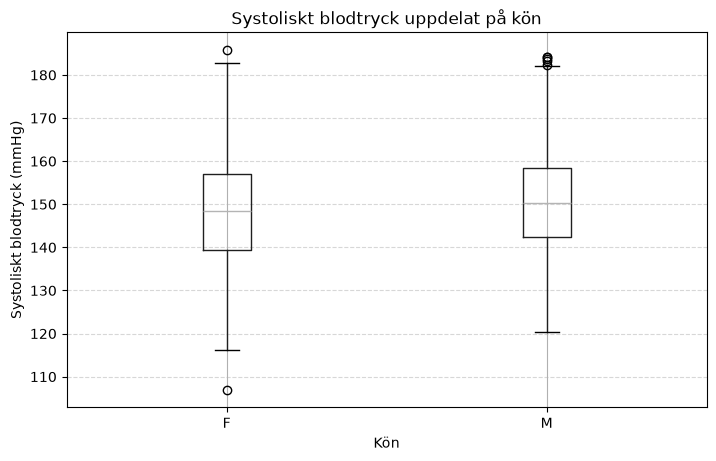

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

df.boxplot(column="systolic_bp", by="sex", ax=ax)

ax.set_title("Systoliskt blodtryck uppdelat på kön")
ax.set_xlabel("Kön")
ax.set_ylabel("Systoliskt blodtryck (mmHg)")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("")
plt.show()

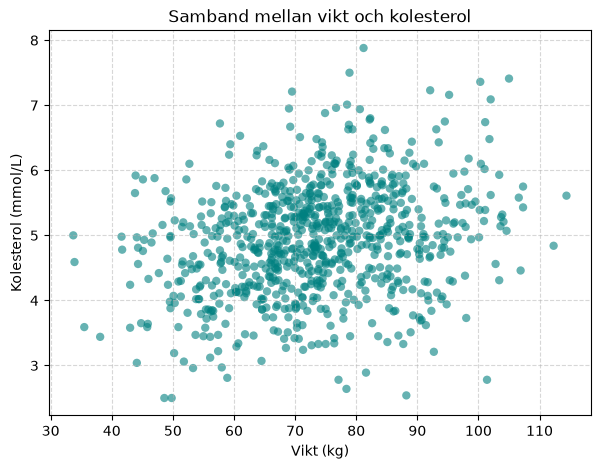

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(df["weight"], df["cholesterol"], alpha=0.6, color='teal', edgecolors='none')

plt.title("Samband mellan vikt och kolesterol")
plt.ylabel("Kolesterol (mmol/L)")
plt.xlabel("Vikt (kg)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Tolkning av visualiseringar

**Rökvanor uppdelat på kön**

Diagrammet visar antalet rökare och icke-rökare uppdelat på kön. Det gör det möjligt att jämföra rökvanorna mellan män och kvinnor.

**Systoliskt blodtryck uppdelat på kön**

Boxploten visar fördelningen av systoliskt blodtryck för män och kvinnor. Medianvärdena ligger nära varandra, men det finns även några avvikande höga värden.

**Samband mellan vikt och kolesterol**

Spridningsdiagrammet visar sambandet mellan vikt och kolesterol. Punkterna är relativt utspridda och inget tydligt starkt linjärt samband kan utläsas direkt från diagrammet.

In [15]:
np.random.seed(42)

p_verklig = df["disease"].mean()

simulerade_personer = np.random.choice([0, 1], size=1000, p=[1 - p_verklig, p_verklig])

p_simulerad = simulerade_personer.mean()

print("Verklig andel:   ", p_verklig)
print("Simulerad andel: ", p_simulerad)

Verklig andel:    0.05875
Simulerad andel:  0.056


### Jämförelse och tolkning

Den observerade andelen personer med sjukdom i datasetet är cirka 5,88 %. Vid simulering av 1 000 nya individer med samma sannolikhet blev den simulerade andelen 5,60 %.

Skillnaden är liten och kan förklaras av slumpmässig variation. Resultatet är därför rimligt utifrån den sannolikhet som användes i simuleringen.

In [16]:
print("Medelvärde:", df['systolic_bp'].mean())
print("Antal (n): ", df['systolic_bp'].count())

Medelvärde: 149.178625
Antal (n):  800


In [17]:
# Rensa bort saknade värden
bp_data = df["systolic_bp"].dropna().values

n = len(bp_data)
mean_bp = np.mean(bp_data)
std_bp = np.std(bp_data, ddof=1)
confidence_level = 0.95

# Metod 1: Normalapproximation / t-fördelning
t_crit = stats.t.ppf((1 + confidence_level) / 2, df=n - 1)

sem = std_bp / np.sqrt(n)

ci_lower_norm = mean_bp - t_crit * sem
ci_upper_norm = mean_bp + t_crit * sem

# Metod 2: Bootstrap
np.random.seed(42)

n_bootstraps = 1000
bootstrap_means = np.empty(n_bootstraps)

for i in range(n_bootstraps):
    bootstrap_sample = np.random.choice(bp_data, size=n, replace=True)
    bootstrap_means[i] = np.mean(bootstrap_sample)

# Percentilmetoden för 95 % konfidensintervall
ci_lower_boot = np.percentile(bootstrap_means, 2.5)
ci_upper_boot = np.percentile(bootstrap_means, 97.5)

# Resultat
print(f"Stickprovsmedelvärde: {mean_bp:.2f} mmHg")
print(f"95% KI (t-fördelning): [{ci_lower_norm:.2f}, {ci_upper_norm:.2f}] mmHg")
print(f"95% KI (Bootstrap, B={n_bootstraps}): [{ci_lower_boot:.2f}, {ci_upper_boot:.2f}] mmHg")

Stickprovsmedelvärde: 149.18 mmHg
95% KI (t-fördelning): [148.29, 150.07] mmHg
95% KI (Bootstrap, B=1000): [148.31, 150.10] mmHg


### Jämförelse av konfidensintervall

Vi beräknade ett 95-procentigt konfidensintervall för det genomsnittliga systoliska blodtrycket med två metoder: t-fördelning och bootstrap.

- **t-fördelning:** 148,29–150,07 mmHg.
- **Bootstrap:** 148,31–150,10 mmHg.

Vi valde t-fördelning eftersom metoden tar hänsyn till osäkerheten i stickprovsmedelvärdet. Bootstrap valdes för att uppskatta osäkerheten genom upprepad slumpmässig sampling med återläggning från vårt dataset.

Båda metoderna gav mycket liknande resultat. Det tyder på att skattningen av medelvärdet är relativt stabil.

Metoderna bygger på olika antaganden, och resultaten förutsätter att observationerna är representativa och tillräckligt oberoende.

In [18]:
# Hypotesprövning: Har rökare högre medelblodtryck?

rokare = df.loc[df["smoker"] == "Yes", "systolic_bp"]
icke_rokare = df.loc[df["smoker"] == "No", "systolic_bp"]

# Ensidigt t-test (Welch)
t_stat, p_value = stats.ttest_ind(
    rokare,
    icke_rokare,
    equal_var=False,
    alternative="greater"
)

print(f"Medelvärde rökare: {rokare.mean():.2f} mmHg")
print(f"Medelvärde icke-rökare: {icke_rokare.mean():.2f} mmHg")
print(f"t-värde: {t_stat:.3f}")
print(f"p-värde: {p_value:.3f}")


Medelvärde rökare: 149.52 mmHg
Medelvärde icke-rökare: 149.05 mmHg
t-värde: 0.450
p-värde: 0.326


### Resultat och tolkning – Hypotesprövning

Vi undersökte om rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare med hjälp av ett ensidigt Welch's t-test.

Medelvärdet för rökare var **149,52 mmHg**, jämfört med **149,05 mmHg** för icke-rökare. Skillnaden var cirka **0,47 mmHg**.

Testet gav ett **p-värde på 0,326**, vilket är högre än signifikansnivån 0,05.

Vi kan därför inte förkasta nollhypotesen (H₀). Resultatet visar inte något statistiskt signifikant stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare i den undersökta populationen.

In [19]:
np.random.seed(42)

high_study = [1, 2, 5]

for m in high_study:
    resultat = []

    for i in range(1000):
        sample1 = np.random.choice(rokare, len(rokare), replace=True) + m
        sample2 = np.random.choice(icke_rokare, len(icke_rokare), replace=True)

        t, p = stats.ttest_ind(
            sample1, sample2,
            equal_var=False,
            alternative="greater"
        )

        resultat.append(p < 0.05)

    power = np.mean(resultat)

    print(f"Ökning: {m} mmHg | Power: {power:.2%}")


Ökning: 1 mmHg | Power: 39.60%
Ökning: 2 mmHg | Power: 77.60%
Ökning: 5 mmHg | Power: 100.00%


### Simulering – Statistisk styrka (Power)

För att undersöka testets statistiska styrka genomfördes 1 000 simuleringar med slumpmässig sampling och återläggning.

Vi använde samma ensidiga Welch's t-test som i hypotesprövningen och simulerade tre olika ökningar av blodtrycket hos rökare.

| Ytterligare ökning | Power |
|---|---|
| 1 mmHg | 39,60 % |
| 2 mmHg | 77,60 % |
| 5 mmHg | 100,00 % |

Resultaten visar att testets statistiska styrka ökar när den antagna skillnaden i blodtryck blir större.

Vid en ökning på 1 mmHg var testets power relativt låg (39,60 %). Vid 2 mmHg ökade den till 77,60 %, medan testet upptäckte en statistiskt signifikant skillnad i samtliga 1000 simuleringar vid 5 mmHg.

Detta visar att större skillnader är lättare att upptäcka statistiskt med samma stickprovsstorlek.

Observera: Ökningarna lades till de observerade blodtrycksvärdena hos rökarna. Simuleringen undersöker därför effekten av ytterligare ökningar utöver den skillnad som redan finns i datasetet.

### Metodval och referenser

Welch's t-test valdes eftersom metoden inte förutsätter lika varians mellan de två grupperna. Ett ensidigt test användes eftersom hypotesen var att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

Konfidensintervallet beräknades med både t-fördelning och bootstrap för att jämföra en parametrisk metod med en resamplingmetod.

**Referenser:**
- [SciPy – ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)
- [SciPy – bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
- [NumPy – random](https://numpy.org/doc/stable/reference/random/index.html)